# Topic 146 — Conditional GAN for medical-image augmentation

## Research question

Can a conditional GAN (cGAN) generate sufficiently diverse **squamous cell carcinoma (SCC)** skin-lesion images to improve SCC prediction on a held-out set of real lesions?

The ISIC 2019 dataset is already labelled by diagnosis, so this notebook uses **supervised categories** rather than unsupervised clustering. Clustering may be useful for exploration, but it cannot replace clinical labels and is not part of the evaluation.

The comparison is controlled:

| Arm | Extra SCC images | What it tells us |
|---|---:|---|
| Real only | 0 | Baseline classifier |
| Repeated real SCC | N resampled real images | Effect of showing SCC more often |
| cGAN SCC | N screened synthetic images | Effect of synthetic diversity beyond repetition |

**Important:** The cGAN is trained only on the training partition. Validation and test partitions contain only real images and are grouped by lesion ID to avoid image/lesion leakage. This is a classroom experiment, not a diagnostic system.

## 1. Setup

Download the approximately 9.1 GB ISIC 2019 training-image archive, training ground truth, and metadata from the [ISIC Challenge data page](https://challenge.isic-archive.com/data/). The dataset is CC-BY-NC; retain its attribution and use it only within that licence.

Expected layout:

```text
data/isic2019/
├── ISIC_2019_Training_Input/
├── ISIC_2019_Training_GroundTruth.csv
└── ISIC_2019_Training_Metadata.csv
```

Use Python 3.11 or 3.12 on macOS. Run the next cell once in the project environment, then restart the Jupyter kernel.

In [13]:
# Run once if dependencies are not installed. Then restart the kernel.
# %pip install -r requirements.txt

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

from src.medical_cgan import (
    ConditionalGenerator, ProjectionDiscriminator, balanced_loader,
    build_training_arms, class_count_table, classifier_transforms,
    configure_mps_memory, evaluate_classifier, export_blinded_realism_panel,
    gan_transform, generate_candidates, group_bootstrap_target_f1,
    group_safe_split, init_gan_weights, load_isic_2019, make_classifier,
    screen_near_duplicates, seed_everything, select_device,
    synthetic_detector_auc, train_cgan, train_classifier, validate_isic_layout,
)

# A full run can take many hours on an 8 GB unified-memory Mac.
# Keep False while checking paths and the split; change to True only to train.
RUN_FULL = True
SEED = 146

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / 'data' / 'isic2019'
IMAGE_DIR = DATA_DIR / 'ISIC_2019_Training_Input'
LABELS_CSV = DATA_DIR / 'ISIC_2019_Training_GroundTruth.csv'
METADATA_CSV = DATA_DIR / 'ISIC_2019_Training_Metadata.csv'
ARTIFACT_DIR = PROJECT_DIR / 'artifacts'

# Conservative defaults for approximately 8 GB of unified memory.
TARGET_CLASS = 'SCC'
GAN_SIZE, GAN_BATCH, GAN_EPOCHS = 128, 8, 80
CLASSIFIER_BATCH, CLASSIFIER_EPOCHS = 8, 12
N_SYNTHETIC_SCC = 600          # about one generated sample per real SCC image
CANDIDATE_MULTIPLIER = 2      # allows near-duplicate rejection
PHASH_REJECT_AT_OR_BELOW = 4


In [15]:
seed_everything(SEED)
DEVICE = select_device()
configure_mps_memory(DEVICE, fraction=0.68)
print('PyTorch:', torch.__version__)
assert DEVICE.type in ('mps', 'cuda'), f'Hardware acceleration required (MPS or CUDA), found: {DEVICE.type}'


Using device: mps
MPS recommended working set: 5.33 GB; cap: 68%
PyTorch: 2.10.0


## 2. Load labels and create a leakage-safe split

The ISIC diagnosis columns are the categories. The `lesion_id` field is used as a group when available, so multiple photographs of one lesion never cross train/validation/test boundaries. The output is approximately 71% train, 14% validation, and 14% test.

In [16]:
validate_isic_layout(IMAGE_DIR, LABELS_CSV, METADATA_CSV)
frame, label_to_index, index_to_label = load_isic_2019(IMAGE_DIR, LABELS_CSV, METADATA_CSV)
assert TARGET_CLASS in label_to_index, f"{TARGET_CLASS} is not in {list(label_to_index)}"
TARGET_LABEL = label_to_index[TARGET_CLASS]

if (ARTIFACT_DIR / "train_split.csv").exists():
    print("Loading existing leakage-safe splits from disk...")
    splits = {name: pd.read_csv(ARTIFACT_DIR / f"{name}_split.csv") for name in ("train", "val", "test")}
else:
    splits = group_safe_split(frame, seed=SEED)
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    for name, split in splits.items():
        split.to_csv(ARTIFACT_DIR / f"{name}_split.csv", index=False)

for name, split in splits.items():
    print(f"{name:10s} images={len(split):5d} lesions={split.group_id.nunique():5d}")
    display(class_count_table(split))


Loading existing leakage-safe splits from disk...
train      images=18623 lesions=10238


,diagnosis,label,images
5,NV,1,9454
4,MEL,0,3314
1,BCC,2,2491
2,BKL,4,1934
0,AK,3,641
6,SCC,7,429
7,VASC,6,191
3,DF,5,169


val        images= 3044 lesions= 1704


,diagnosis,label,images
5,NV,1,1551
4,MEL,0,515
1,BCC,2,370
2,BKL,4,325
0,AK,3,130
6,SCC,7,96
7,VASC,6,29
3,DF,5,28


test       images= 3664 lesions= 1989


,diagnosis,label,images
5,NV,1,1870
4,MEL,0,693
1,BCC,2,462
2,BKL,4,365
6,SCC,7,103
0,AK,3,96
3,DF,5,42
7,VASC,6,33


Target minority class: SCC | training examples: 429


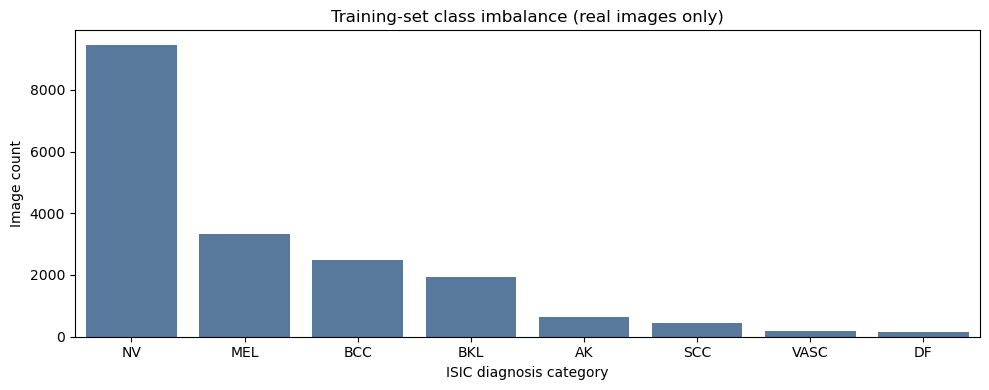

In [17]:
counts = class_count_table(splits['train'])
plt.figure(figsize=(10, 4))
sns.barplot(data=counts, x='diagnosis', y='images', color='#4c78a8')
plt.title('Training-set class imbalance (real images only)')
plt.xlabel('ISIC diagnosis category'); plt.ylabel('Image count')
plt.tight_layout()
print('Target minority class:', TARGET_CLASS, '| training examples:', int((splits['train'].label == TARGET_LABEL).sum()))

## 3. cGAN design

The generator receives random noise plus a diagnosis embedding. The discriminator receives an image and diagnosis embedding. This is a compact, conditional DCGAN with a projection discriminator and hinge loss. It is intentionally limited to 128×128 and batch size 8 for an 8 GB Mac.

The GAN's training batches are class-balanced so rare labels are represented. We generate **only SCC** after training. Saved sample grids are mandatory evidence for detecting collapse; a low GAN loss alone does not prove realism.

In [18]:
GAN_LOADER = balanced_loader(splits['train'], gan_transform(GAN_SIZE), GAN_BATCH, SEED, shuffle=True)
generator = ConditionalGenerator(n_classes=len(label_to_index), z_dim=128, base=32).apply(init_gan_weights)
discriminator = ProjectionDiscriminator(n_classes=len(label_to_index), base=32).apply(init_gan_weights)
print('Generator parameters:', sum(p.numel() for p in generator.parameters()))
print('Discriminator parameters:', sum(p.numel() for p in discriminator.parameters()))

# One fixed sample per category gives a consistent visual training record.
SAMPLE_LABELS = list(range(len(label_to_index)))

Generator parameters: 4123360
Discriminator parameters: 2792929


Loaded existing cGAN training history from /Users/ameersohielmomingmail.com/Gen AI/Jury 1/artifacts/cgan/loss_history.csv (80 epochs completed).


,epoch,generator_loss,discriminator_loss
75,76,0.170955,2.000077
76,77,0.182796,2.000091
77,78,0.123289,2.000068
78,79,0.078906,2.000068
79,80,0.107664,2.000114


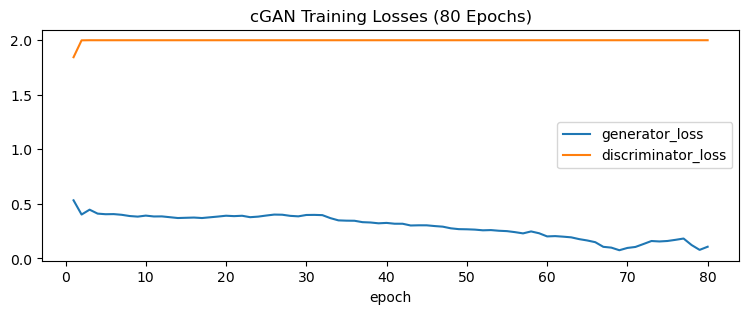

In [19]:
CGAN_DIR = ARTIFACT_DIR / 'cgan'
if (CGAN_DIR / 'loss_history.csv').exists():
    print(f"Loaded existing cGAN training history from {CGAN_DIR / 'loss_history.csv'} (80 epochs completed).")
    gan_history = pd.read_csv(CGAN_DIR / 'loss_history.csv')
    display(gan_history.tail())
    gan_history.set_index('epoch')[['generator_loss', 'discriminator_loss']].plot(figsize=(9, 3), title='cGAN Training Losses (80 Epochs)')
    plt.show()
elif RUN_FULL:
    gan_history = train_cgan(
        generator, discriminator, GAN_LOADER, DEVICE, GAN_EPOCHS, CGAN_DIR,
        sample_labels=SAMPLE_LABELS, sample_every=5, lr=2e-4,
    )
    gan_history.to_csv(CGAN_DIR / 'loss_history.csv', index=False)
    display(gan_history.tail())
    gan_history.set_index('epoch')[['generator_loss', 'discriminator_loss']].plot(figsize=(9, 3), title='cGAN losses')
else:
    print('Smoke/data-audit mode. Set RUN_FULL = True to train the cGAN.')


## 4. Generate SCC candidates and screen them

Candidates are compared with **real SCC training images** and previously accepted synthetic images using perceptual hashes. A candidate that is too similar is rejected. We also fit a deliberately simple real-vs-synthetic detector from colour/edge statistics. A high AUC is a warning that images are easily distinguishable; it is not a measure of clinical realism.

Do not use generated images if the saved grids show collapse, implausible borders, repeated shapes, rulers/hair artefacts, or the detector indicates a strong synthetic domain shift.

In [20]:
SYNTHETIC_DIR = ARTIFACT_DIR / 'synthetic_scc'
MANIFEST_PATH = SYNTHETIC_DIR / 'screening_manifest.csv'

if MANIFEST_PATH.exists():
    print(f"Loaded existing synthetic screening manifest from {MANIFEST_PATH}")
    synthetic_manifest = pd.read_csv(MANIFEST_PATH)
    print(f"Candidate SCC images: {len(synthetic_manifest)}, Accepted: {synthetic_manifest.accepted.sum()}")
elif RUN_FULL:
    checkpoint = torch.load(CGAN_DIR / 'cgan_latest.pt', map_location=DEVICE)
    generator.load_state_dict(checkpoint['generator'])
    candidate_paths = generate_candidates(
        generator, TARGET_LABEL, N_SYNTHETIC_SCC * CANDIDATE_MULTIPLIER, DEVICE,
        SYNTHETIC_DIR / 'candidates', batch_size=CLASSIFIER_BATCH,
    )
    real_scc_paths = splits['train'].query('label == @TARGET_LABEL').image_path
    synthetic_manifest = screen_near_duplicates(real_scc_paths, candidate_paths, threshold=PHASH_REJECT_AT_OR_BELOW)
    synthetic_manifest.to_csv(MANIFEST_PATH, index=False)
    print(f"Candidate images: {len(candidate_paths)}, accepted: {synthetic_manifest.accepted.sum()}")
else:
    print('Set RUN_FULL = True to generate and screen synthetic SCC candidates.')


Loaded existing synthetic screening manifest from /Users/ameersohielmomingmail.com/Gen AI/Jury 1/artifacts/synthetic_scc/screening_manifest.csv
Candidate SCC images: 1200, Accepted: 963


## 5. Classifier experiment

All arms use an ImageNet-initialized EfficientNet-B0, the same augmentations, the same class-balanced sampler, the same validation selection rule, and the same real test set. The balanced sampler is held constant so the cGAN arm cannot win merely because SCC is sampled more frequently. It can only win through additional image diversity.

Metrics: accuracy, balanced accuracy, macro F1, and SCC precision, recall, F1, and PR-AUC. The primary minority-class answer is SCC F1/recall/PR-AUC—not raw accuracy.

In [21]:
TRAIN_TRANSFORM, EVAL_TRANSFORM = classifier_transforms(224)
VAL_LOADER = balanced_loader(splits["val"], EVAL_TRANSFORM, CLASSIFIER_BATCH, SEED, shuffle=False)
TEST_LOADER = balanced_loader(splits["test"], EVAL_TRANSFORM, CLASSIFIER_BATCH, SEED, shuffle=False)
synthetic_manifest = pd.read_csv(MANIFEST_PATH)
arms = build_training_arms(splits["train"], synthetic_manifest, TARGET_LABEL, N_SYNTHETIC_SCC, SEED)
results, outputs_by_arm = [], {}

for arm_name, arm_frame in arms.items():
    ckpt_path = ARTIFACT_DIR / f"{arm_name}_efficientnet_b0.pt"
    if ckpt_path.exists():
        print(f"Loading trained checkpoint for {arm_name} from {ckpt_path.name}...")
        classifier = make_classifier(n_classes=len(label_to_index), pretrained=False).to(DEVICE)
        classifier.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    elif RUN_FULL:
        print(f"Training {arm_name}: {len(arm_frame)} records...")
        seed_everything(SEED)
        train_loader = balanced_loader(arm_frame, TRAIN_TRANSFORM, CLASSIFIER_BATCH, SEED, shuffle=True)
        classifier = make_classifier(n_classes=len(label_to_index), pretrained=True)
        classifier, history = train_classifier(
            classifier, train_loader, VAL_LOADER, DEVICE, TARGET_LABEL, CLASSIFIER_EPOCHS, learning_rate=2e-4
        )
        history.to_csv(ARTIFACT_DIR / f"{arm_name}_history.csv", index=False)
        torch.save(classifier.state_dict(), ckpt_path)
    else:
        continue
    print(f"Evaluating {arm_name} on 3,664 held-out real test lesions...")
    metrics, outputs = evaluate_classifier(classifier, TEST_LOADER, DEVICE, TARGET_LABEL)
    low, high = group_bootstrap_target_f1(outputs, splits["test"].group_id.to_numpy(), TARGET_LABEL)
    metrics.update({"arm": arm_name, "target_f1_ci_low": low, "target_f1_ci_high": high})
    results.append(metrics); outputs_by_arm[arm_name] = outputs

comparison_csv = ARTIFACT_DIR / "classifier_comparison.csv"
if comparison_csv.exists():
    results_df = pd.read_csv(comparison_csv).set_index("arm")
else:
    results_df = pd.DataFrame(results).set_index("arm").sort_index()
    results_df.to_csv(comparison_csv)
display(results_df[["target_recall", "target_precision", "target_f1", "target_pr_auc", "macro_f1", "balanced_accuracy"]].round(3))


Loading trained checkpoint for real_only from real_only_efficientnet_b0.pt...
Evaluating real_only on 3,664 held-out real test lesions...
Loading trained checkpoint for repeated_real_scc from repeated_real_scc_efficientnet_b0.pt...
Evaluating repeated_real_scc on 3,664 held-out real test lesions...
Loading trained checkpoint for cgan_scc from cgan_scc_efficientnet_b0.pt...
Evaluating cgan_scc on 3,664 held-out real test lesions...


,target_recall,target_precision,target_f1,target_pr_auc,macro_f1,balanced_accuracy
arm,,,,,,
cgan_scc,0.272,0.354,0.308,0.258,0.505,0.521
real_only,0.311,0.410,0.354,0.340,0.523,0.548
repeated_real_scc,0.282,0.337,0.307,0.246,0.500,0.523


,target_recall,target_precision,target_f1,target_pr_auc,macro_f1,balanced_accuracy
arm,,,,,,
cgan_scc,0.272,0.354,0.308,0.258,0.505,0.521
real_only,0.311,0.410,0.354,0.340,0.523,0.548
repeated_real_scc,0.282,0.337,0.307,0.246,0.500,0.523


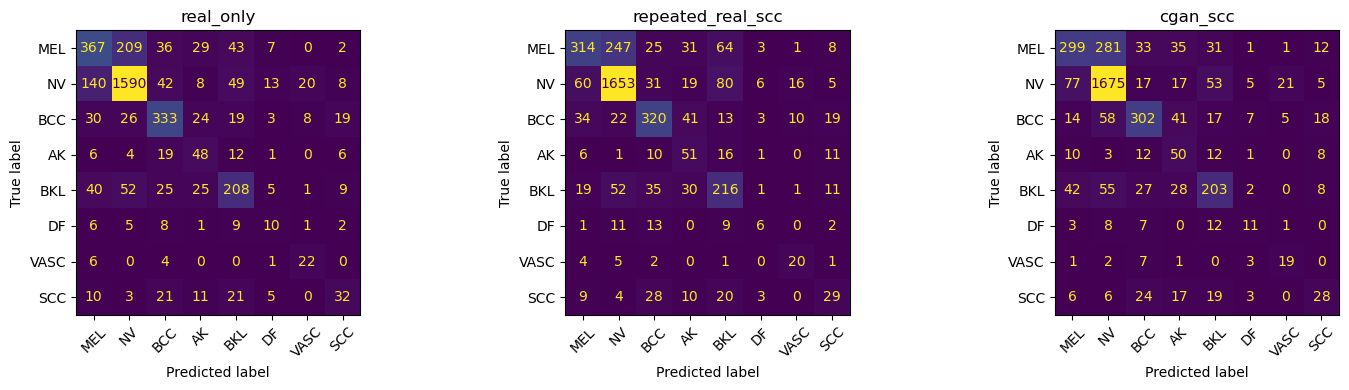

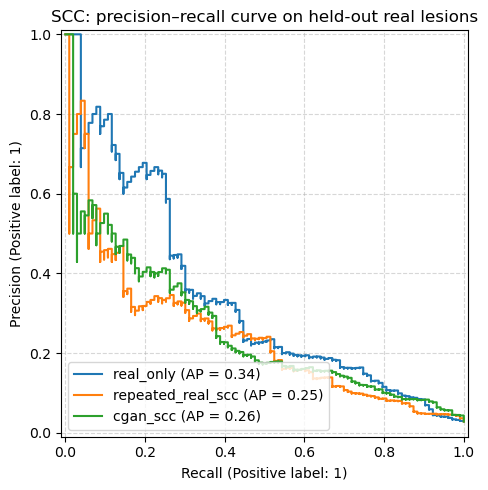

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

# Result figures for the jury presentation
metric_columns = ['target_recall', 'target_precision', 'target_f1', 'target_pr_auc', 'macro_f1', 'balanced_accuracy']
display(results_df[metric_columns].round(3))

if outputs_by_arm:
    fig, axes = plt.subplots(1, len(outputs_by_arm), figsize=(5 * len(outputs_by_arm), 4))
    if len(outputs_by_arm) == 1:
        axes = [axes]
    for axis, (arm_name, output) in zip(axes, outputs_by_arm.items()):
        # Matches the active classes (8) so there is no label mismatch
        active_classes = sorted(np.unique(np.concatenate([output['y_true'], output['y_pred']])))
        ConfusionMatrixDisplay.from_predictions(
            output['y_true'], output['y_pred'],
            labels=active_classes,
            display_labels=[index_to_label[i] for i in active_classes],
            xticks_rotation=45, colorbar=False, ax=axis
        )
        axis.set_title(arm_name)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(figsize=(6, 5))
    for arm_name, output in outputs_by_arm.items():
        PrecisionRecallDisplay.from_predictions(
            output['y_true'] == TARGET_LABEL, output['probabilities'][:, TARGET_LABEL],
            name=arm_name, ax=ax
        )
    ax.set_title(f"{TARGET_CLASS}: precision–recall curve on held-out real lesions")
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

## 6. Blinded classroom realism assessment

This exports a shuffled panel of real and synthetic SCC images plus a separate answer key. Ask classmates only whether each image appears **real, synthetic, or unsure**, and which visible artefacts they notice. Do not ask them to diagnose lesions, collect names, or make claims about clinical realism. Keep the answer key private until responses are collected.

In [24]:
real_scc_paths = splits['train'].query('label == @TARGET_LABEL').image_path.tolist()
accepted_paths = synthetic_manifest.query('accepted').image_path.tolist()[:N_SYNTHETIC_SCC]
realism_dir = ARTIFACT_DIR / 'realism_survey'
if not (realism_dir / 'PRIVATE_answer_key.csv').exists():
    answer_key = export_blinded_realism_panel(real_scc_paths, accepted_paths, realism_dir, per_source=12, seed=SEED)
else:
    answer_key = realism_dir / 'PRIVATE_answer_key.csv'
print(f"Blinded panel of 24 images exported to: {realism_dir}")
print("Share panel_*.png only. Keep this file private until the survey ends:", answer_key)


Blinded panel of 24 images exported to: /Users/ameersohielmomingmail.com/Gen AI/Jury 1/artifacts/realism_survey
Share panel_*.png only. Keep this file private until the survey ends: /Users/ameersohielmomingmail.com/Gen AI/Jury 1/artifacts/realism_survey/PRIVATE_answer_key.csv


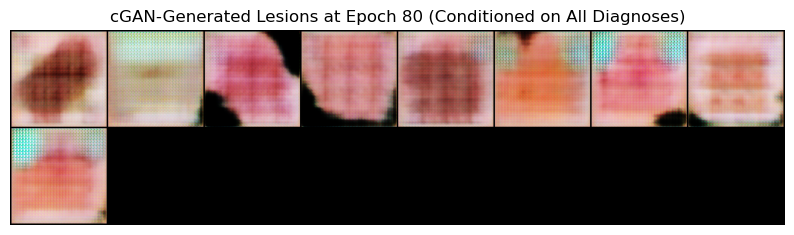

In [25]:
# Optional: Display the actual 80-epoch generated image grid
from PIL import Image
samples_img = Image.open(CGAN_DIR / "samples_epoch_080.png")
plt.figure(figsize=(10, 5))
plt.imshow(samples_img)
plt.axis("off")
plt.title("cGAN-Generated Lesions at Epoch 80 (Conditioned on All Diagnoses)")
plt.show()

## 7. How to present and interpret the result

Use `artifacts/classifier_comparison.csv` as the final table. State that cGAN augmentation improved the minority class only if SCC F1, recall, and PR-AUC improve over both **real only** and **repeated real SCC**, with the group-bootstrap confidence interval reported. Repeat the full experiment with at least three seeds before making a strong claim.

### Jury question: Did augmentation improve the minority class?
Answer from the held-out real test set, specifically SCC F1/recall/PR-AUC and confidence intervals. Do not answer from GAN loss, visual samples, training accuracy, or the validation set alone.

### Jury question: What is the danger of synthetic medical artefacts?
A cGAN can reproduce or invent class-correlated shortcuts: hair, rulers, vignettes, colour casts, JPEG patterns, acquisition-device cues, and demographic/site bias. The classifier may then learn those shortcuts rather than lesion morphology. Good in-dataset performance and a realistic-looking image grid do not establish clinical validity or external generalisation.

### Required limitations slide
- Visual survey and perceptual hashes are quality screens, not medical validation.
- A high real-vs-synthetic detector AUC flags domain shift.
- No synthetic image is allowed in validation or test data.
- This experiment needs external real-world validation before any clinical conclusion.